# 4. Datos por sujeto y descriptores espectrales

Este notebook **cierra el paso 5** (valores representativos por sujeto, experimento, canal y banda) y calcula los descriptores que se usan en los pasos 6 a 8:

1. **Potencia absoluta** por banda.
2. **Potencia relativa** por banda.
3. **Diferencia pareada** nativo − no nativo, por sujeto.
4. **Tamaño de efecto** (Cohen's $d_z$) con intervalo de confianza.

## 4.0 Qué es cada descriptor y para qué sirve

**PSD (densidad espectral de potencia).** Dice cuánta potencia tiene la señal en cada frecuencia, en µV²/Hz. Se estima con Welch: se corta la señal en ventanas solapadas, se calcula la FFT de cada una y se promedian los espectros. Promediar reduce la varianza de la estimación a cambio de resolución en frecuencia (con 20 s de ventana, Δf = 0,05 Hz).

**Potencia absoluta de banda** — $P_{abs}(b) = \int_{f_1}^{f_2} \text{PSD}(f)\,df$, en µV².
- *Qué significa:* cuánta energía oscilatoria hay en ese ritmo (δ, θ, α, β, γ baja). Es el área bajo la PSD dentro de la banda.
- *Para qué se usa:* es la medida "física" directa de cada ritmo. Si sube la potencia α en P4, hay más actividad alfa (más sincronización) en la zona parietal.
- *Cuidado:* depende mucho de factores que no son cerebrales (impedancia del electrodo, grosor del cráneo, pelo), y por eso varía muchísimo **entre** sujetos. Se compara **dentro** del mismo sujeto y en escala logarítmica. El log convierte cocientes en restas y hace que la distribución sea más simétrica.

**Potencia relativa de banda** — $P_{rel}(b) = P_{abs}(b) \,/\, P_{total}$, con $P_{total}$ = potencia entre 0,5 y 40 Hz.
- *Qué significa:* qué fracción de la potencia total está en esa banda (el "reparto" del espectro).
- *Para qué se usa:* normaliza las diferencias de amplitud entre sujetos. Es el estándar para comparar perfiles espectrales entre personas o condiciones.
- *Cuidado:* las 5 bandas **suman 1**. Si una sube, alguna otra tiene que bajar aunque no haya cambiado nada en ella (por ejemplo, un artefacto que infla δ hace bajar α relativa). Por eso se mira siempre junto con la absoluta: si las dos se mueven igual, el efecto es más creíble.

**Diferencia pareada por sujeto** — $\Delta_i = X_i^{nativo} - X_i^{no\,nativo}$ para cada sujeto $i$, canal y banda.
- Para la absoluta se usa $\Delta_i = \log_{10} P^{nat}_i - \log_{10} P^{no\,nat}_i = \log_{10}\!\left(P^{nat}_i / P^{no\,nat}_i\right)$. Δ = 0,1 equivale a +26 % de potencia con la canción nativa ($10^{0,1} = 1,26$).
- Para la relativa, $\Delta_i$ se expresa en **puntos porcentuales**.
- *Para qué se usa:* es la variable central del diseño. Al restar dentro del sujeto se cancela todo lo que es propio de esa persona (amplitud, anatomía, electrodos) y queda solo el efecto de la condición. **Signo: Δ > 0 significa más potencia con la canción nativa.**

**Tamaño de efecto (Cohen's $d_z$)** — $d_z = \bar\Delta \,/\, s_\Delta$ (media de las diferencias dividida por su desvío).
- *Qué significa:* cuán grande es el cambio medio **comparado con lo que varía entre sujetos**. $d_z = 1$ indica que el cambio medio es igual a un desvío. Referencias habituales: 0,2 chico, 0,5 mediano, 0,8 grande.
- *Para qué se usa:* a diferencia del p-valor, no depende del tamaño de la muestra, y por eso permite comparar la magnitud del efecto entre canales y bandas. Con n ≈ 19 los p-valores van a ser inestables, así que el $d_z$ con su **intervalo de confianza** (bootstrap) es lo más informativo para reportar. Si el IC cruza el 0, no se puede afirmar el signo del efecto.
- Complemento intuitivo: el **% de sujetos con Δ > 0**. Si es cercano a 50 %, no hay un efecto consistente.

| Banda | Rango | Asociaciones típicas |
|----|----|----|
| δ | 0,5–4 Hz | Procesos lentos |
| θ | 4–8 Hz | Memoria, emoción, carga cognitiva (frontal medial) |
| α | 8–13 Hz | Inhibición / reposo; **baja** con atención activa |
| β | 13–30 Hz | Procesamiento activo, motor |
| γ baja | 30–40 Hz | Integración (semántica, perceptual) |

## 4.1 Configuración y carga

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as ss

RUTA_DATOS = '../datos/Datos_Filtrados'
RUTA_META  = '../datos'
RUTA_OUT   = '../resultados'
os.makedirs(RUTA_OUT, exist_ok=True)

FS = 200
NPERSEG = 4000              # 20 s, igual que en el paso 5
NOVERLAP = NPERSEG // 2     # 50 %
CANALES = ['T7', 'F8', 'Cz', 'P4']
CONDICIONES = {'ex05': 'nativo', 'ex06': 'no_nativo'}
BANDAS = {
    'delta': (0.5, 4),
    'theta': (4, 8),
    'alfa':  (8, 13),
    'beta':  (13, 30),
    'gamma': (30, 40),       # gamma baja (limitada por el pasabanda de 40 Hz)
}
RANGO_TOTAL = (0.5, 40)
SUJETOS_EXCLUIDOS = ['s19']  # ambigüedad de lengua materna (notebook 01)

### Metadatos: qué canción escuchó cada sujeto
Según el README del dataset, los italianos escuchan la canción (Halleluja, en todos los casos) en árabe como "no nativa" y todos los demás escuchan la canción en italiano como "no nativa". La canción nativa es la de su propio idioma. Esto define tres grupos:

| Grupo | Canción nativa | Canción no nativa |
|---|---|---|
| italiano | italiano | árabe |
| árabe | árabe | italiano |
| otro (letón, inglés, urdu) | la propia | italiano |

Italianos y árabes forman un **diseño cruzado**: las mismas dos canciones, con los roles invertidos. Sirve para separar el efecto del *idioma* del efecto de la *canción*. También se marca a quienes declaran hablar fluido el idioma "no nativo" (útil para el paso 8).

In [13]:
meta = pd.read_csv(os.path.join(RUTA_META, 'Subjects.csv'))
meta.columns = meta.columns.str.strip()
meta['sujeto'] = meta['Subject ID'].str.strip().str.lower()
meta['idioma_nativo'] = meta['Mother Language'].str.strip()
meta['comments'] = meta['comments'].fillna('').str.strip()

def grupo(idioma):
    return {'Italian': 'italiano', 'Arabic': 'arabe'}.get(idioma, 'otro')

meta['grupo'] = meta['idioma_nativo'].map(grupo)
meta['cancion_nativa'] = meta['idioma_nativo']
meta['cancion_no_nativa'] = np.where(meta['idioma_nativo'] == 'Italian', 'Arabic', 'Italian')
meta['entiende_no_nativo'] = meta.apply(
    lambda r: f"fluent in {r['cancion_no_nativa'].lower()}" in r['comments'].lower(), axis=1)

meta = meta[~meta['sujeto'].isin(SUJETOS_EXCLUIDOS)].reset_index(drop=True)
meta_cols = ['sujeto', 'idioma_nativo', 'grupo', 'cancion_nativa', 'cancion_no_nativa', 'entiende_no_nativo']
display(meta[meta_cols])
print(meta['grupo'].value_counts().to_string())

,sujeto,idioma_nativo,grupo,cancion_nativa,cancion_no_nativa,entiende_no_nativo
0,s01,Italian,italiano,Italian,Arabic,False
1,s02,Italian,italiano,Italian,Arabic,False
2,s03,Arabic,arabe,Arabic,Italian,False
3,s04,Arabic,arabe,Arabic,Italian,False
4,s05,Arabic,arabe,Arabic,Italian,False
5,s06,Arabic,arabe,Arabic,Italian,False
6,s07,Latvian,otro,Latvian,Italian,False
7,s08,Italian,italiano,Italian,Arabic,False
8,s09,Arabic,arabe,Arabic,Italian,False
9,s10,Italian,italiano,Italian,Arabic,False


grupo
arabe       8
italiano    7
otro        4


## 4.2 PSD por sujeto, condición y canal
Se usa `scipy.signal.welch` con `scaling='density'`, que devuelve la PSD en µV²/Hz. La función manual `welch_per` del notebook 03 implementa el mismo método y da el mismo resultado, lo que se verificó con `np.allclose` contra SciPy en el mismo notebook.

Nota: `s05_ex05` dura ~200 s (el resto, 120 s). La PSD es una *densidad*, así que no depende de la duración. Solo se promedian más ventanas.

In [14]:
sujetos = meta['sujeto'].tolist()
freq = None
PSD = np.full((len(sujetos), len(CONDICIONES), len(CANALES), NPERSEG // 2 + 1), np.nan)
duracion = {}

for i, s in enumerate(sujetos):
    for j, ex in enumerate(CONDICIONES):
        df = pd.read_csv(os.path.join(RUTA_DATOS, f'{s}_{ex}.csv'), index_col=0)
        duracion[(s, ex)] = len(df) / FS
        for k, ch in enumerate(CANALES):
            f, pxx = ss.welch(df[ch].to_numpy(float), fs=FS, window='hann',
                              nperseg=NPERSEG, noverlap=NOVERLAP,
                              detrend='constant', scaling='density')
            PSD[i, j, k] = pxx
            freq = f

print('Forma de PSD (sujeto, condición, canal, frecuencia):', PSD.shape)
print(f'Resolución en frecuencia: {freq[1]:.3f} Hz')
print('Duraciones distintas de 120 s:', {k: v for k, v in duracion.items() if abs(v - 120) > 1})
assert not np.isnan(PSD).any()

np.savez_compressed(os.path.join(RUTA_OUT, 'psd_por_sujeto.npz'),
                    freq=freq, psd=PSD, sujetos=np.array(sujetos),
                    condiciones=np.array(list(CONDICIONES.values())),
                    canales=np.array(CANALES))

Forma de PSD (sujeto, condición, canal, frecuencia): (19, 2, 4, 2001)
Resolución en frecuencia: 0.050 Hz
Duraciones distintas de 120 s: {('s05', 'ex05'): 200.57}


## 4.3 Potencia absoluta y relativa por banda
Cada banda se integra como suma de rectángulos ($\sum \text{PSD}\cdot\Delta f$) con intervalos semiabiertos $[f_1, f_2)$, así ningún bin se cuenta en dos bandas y las 5 relativas suman exactamente 1.

In [15]:
df_f = freq[1] - freq[0]

def potencia(psd, lo, hi, incluir_hi=False):
    m = (freq >= lo) & ((freq <= hi) if incluir_hi else (freq < hi))
    return psd[..., m].sum(axis=-1) * df_f

P_total = potencia(PSD, *RANGO_TOTAL, incluir_hi=True)            # (suj, cond, canal)
filas = []
for b, (lo, hi) in BANDAS.items():
    P_b = potencia(PSD, lo, hi, incluir_hi=(hi == RANGO_TOTAL[1]))
    for i, s in enumerate(sujetos):
        for j, cond in enumerate(CONDICIONES.values()):
            for k, ch in enumerate(CANALES):
                filas.append(dict(sujeto=s, condicion=cond, canal=ch, banda=b,
                                  p_abs=P_b[i, j, k], p_total=P_total[i, j, k],
                                  p_rel=P_b[i, j, k] / P_total[i, j, k]))

bandas_df = pd.DataFrame(filas).merge(meta[meta_cols], on='sujeto')
bandas_df['log10_p_abs'] = np.log10(bandas_df['p_abs'])
orden_b = list(BANDAS)
bandas_df['banda'] = pd.Categorical(bandas_df['banda'], orden_b, ordered=True)

# chequeo: las relativas suman 1
suma = bandas_df.groupby(['sujeto', 'condicion', 'canal'], observed=True)['p_rel'].sum()
assert np.allclose(suma, 1), suma.describe()

bandas_df.to_csv(os.path.join(RUTA_OUT, 'potencia_bandas_largo.csv'), index=False)
print(f'{len(bandas_df)} filas = {len(sujetos)} sujetos × 2 condiciones × 4 canales × 5 bandas')
bandas_df.head()

760 filas = 19 sujetos × 2 condiciones × 4 canales × 5 bandas


,sujeto,condicion,canal,banda,p_abs,p_total,p_rel,idioma_nativo,grupo,cancion_nativa,cancion_no_nativa,entiende_no_nativo,log10_p_abs
0,s01,nativo,T7,delta,23.022632,64.602298,0.356375,Italian,italiano,Italian,Arabic,False,1.362155
1,s01,nativo,F8,delta,2627.557659,3141.188156,0.836485,Italian,italiano,Italian,Arabic,False,3.419552
2,s01,nativo,Cz,delta,19.236079,51.892355,0.370692,Italian,italiano,Italian,Arabic,False,1.284117
3,s01,nativo,P4,delta,14.080395,47.662320,0.295420,Italian,italiano,Italian,Arabic,False,1.148615
4,s01,no_nativo,T7,delta,26.638893,57.695520,0.461715,Italian,italiano,Italian,Arabic,False,1.425516


### Chequeo de cordura
Mediana (entre sujetos) de la potencia relativa en %. Rangos orientativos en adulto despierto: δ 20–40 %, θ 10–20 %, α 15–35 % (más alta en zonas posteriores o con ojos cerrados), β 15–25 %, γ baja 2–8 %. Valores muy fuera de rango sugieren artefacto.

In [16]:
tabla_rel = (bandas_df.pivot_table(index=['canal', 'condicion'], columns='banda',
                                   values='p_rel', aggfunc='median', observed=True) * 100).round(1)
display(tabla_rel.reindex(CANALES, level=0))

print('Potencia absoluta (mediana entre sujetos, µV²):')
display(bandas_df.pivot_table(index=['canal', 'condicion'], columns='banda',
                              values='p_abs', aggfunc='median', observed=True)
        .reindex(CANALES, level=0).round(2))

# Registros sospechosos: γ relativa > 15 % o δ relativa > 60 %
sosp = bandas_df[((bandas_df.banda == 'gamma') & (bandas_df.p_rel > 0.15)) |
                 ((bandas_df.banda == 'delta') & (bandas_df.p_rel > 0.60))]
print('Registros con valores sospechosos:')
display(sosp[['sujeto', 'condicion', 'canal', 'banda', 'p_rel']].round(3))

banda            delta  theta  alfa  beta  gamma
canal condicion                                 
T7    nativo      29.4    9.8  32.8  20.4    4.1
      no_nativo   28.9   10.7  35.9  20.8    3.6
F8    nativo      40.3    8.7  21.9  15.7    3.5
      no_nativo   37.8    9.4  25.6  15.9    3.0
Cz    nativo      27.9   11.7  38.9  16.4    2.6
      no_nativo   30.3   12.5  39.0  15.9    2.6
P4    nativo      18.3    8.0  56.7  15.6    2.5
      no_nativo   20.0    7.7  53.9  15.0    2.7

Potencia absoluta (mediana entre sujetos, µV²):


banda            delta  theta   alfa  beta  gamma
canal condicion                                  
T7    nativo      6.15   3.03  12.22  5.63   1.25
      no_nativo   7.78   3.25  11.52  5.82   1.05
F8    nativo     13.72   3.24  10.12  5.47   1.35
      no_nativo  13.71   3.19  10.72  5.11   1.00
Cz    nativo      9.00   4.39  13.84  5.92   0.91
      no_nativo   9.59   4.24  12.01  5.82   0.83
P4    nativo      7.10   2.88  22.37  6.65   0.95
      no_nativo   7.34   3.13  21.89  6.69   0.92

Registros con valores sospechosos:


,sujeto,condicion,canal,banda,p_rel
1,s01,nativo,F8,delta,0.836
5,s01,no_nativo,F8,delta,0.899
9,s02,nativo,F8,delta,0.763
13,s02,no_nativo,F8,delta,0.777
32,s05,nativo,T7,delta,0.838
33,s05,nativo,F8,delta,0.867
121,s16,nativo,F8,delta,0.824
124,s16,no_nativo,T7,delta,0.658
125,s16,no_nativo,F8,delta,0.827
126,s16,no_nativo,Cz,delta,0.662


### Verificación contra la tabla del notebook 03
Se repite el cálculo del notebook 03 (mediana entre sujetos de la PSD → bandas) para cada canal. La fila de **P4** coincide con su tabla (α ≈ 52 % nativo vs 49 % no nativo). Las pequeñas diferencias vienen de cómo se integran los bordes de banda. Los otros tres canales nunca se habían calculado.

In [17]:
filas = []
for j, cond in enumerate(CONDICIONES.values()):
    for k, ch in enumerate(CANALES):
        med = np.median(PSD[:, j, k], axis=0)
        p = {b: potencia(med, lo, hi, incluir_hi=(hi == 40)) for b, (lo, hi) in BANDAS.items()}
        tot = sum(p.values())
        filas.append({'canal': ch, 'condicion': cond, **{b: 100 * v / tot for b, v in p.items()}})
display(pd.DataFrame(filas).set_index(['canal', 'condicion']).round(2))

,,delta,theta,alfa,beta,gamma
canal,condicion,,,,,
T7,nativo,26.68,11.00,36.75,21.17,4.40
F8,nativo,42.78,10.88,24.78,17.41,4.16
Cz,nativo,27.85,13.70,38.59,16.89,2.97
P4,nativo,20.08,8.70,51.93,16.51,2.78
T7,no_nativo,29.83,11.95,32.84,21.10,4.27
F8,no_nativo,42.76,11.59,24.85,17.09,3.70
Cz,no_nativo,31.01,14.14,34.90,16.86,3.10
P4,no_nativo,23.03,9.14,48.91,16.18,2.73


## 4.4 PSD típica por canal: nativo vs no nativo
Mediana entre sujetos con rango intercuartil, para ver de dónde salen los números. La forma esperada es potencia decreciente con la frecuencia (~1/f) con un pico en α.

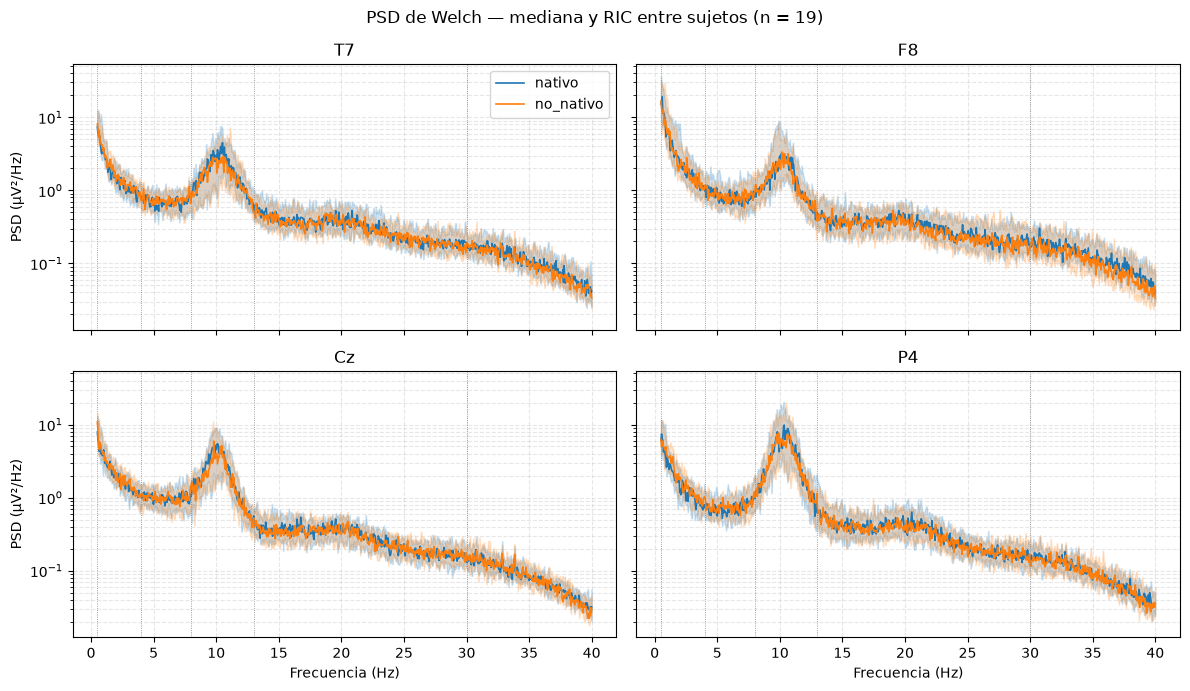

In [18]:
colores = {'nativo': 'tab:blue', 'no_nativo': 'tab:orange'}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
m = (freq >= 0.5) & (freq <= 40)
for ax, (k, ch) in zip(axes.flat, enumerate(CANALES)):
    for j, cond in enumerate(CONDICIONES.values()):
        x = PSD[:, j, k][:, m]
        ax.semilogy(freq[m], np.median(x, 0), color=colores[cond], lw=1.2, label=cond)
        ax.fill_between(freq[m], *np.percentile(x, [25, 75], 0), color=colores[cond], alpha=0.2)
    for lo, hi in BANDAS.values():
        ax.axvline(lo, color='gray', lw=0.6, ls=':')
    ax.set_title(ch); ax.grid(True, which='both', ls='--', alpha=0.3)
for ax in axes[1]: ax.set_xlabel('Frecuencia (Hz)')
for ax in axes[:, 0]: ax.set_ylabel('PSD (µV²/Hz)')
axes[0, 0].legend()
fig.suptitle(f'PSD de Welch — mediana y RIC entre sujetos (n = {len(sujetos)})')
plt.tight_layout(); plt.show()

## 4.5 Diferencia pareada por sujeto (nativo − no nativo)
- `d_log_abs` = $\log_{10}(P^{nat}/P^{no\,nat})$. Se muestra también como % de cambio: $(10^{\Delta}-1)\cdot 100$.
- `d_rel_pp` = diferencia de potencia relativa en puntos porcentuales.

In [19]:
idx = ['sujeto', 'canal', 'banda']
w_log = bandas_df.pivot_table(index=idx, columns='condicion', values='log10_p_abs', observed=True)
w_rel = bandas_df.pivot_table(index=idx, columns='condicion', values='p_rel', observed=True)

dif = pd.DataFrame({
    'd_log_abs': w_log['nativo'] - w_log['no_nativo'],
    'd_rel_pp': (w_rel['nativo'] - w_rel['no_nativo']) * 100,
}).reset_index()
dif['cambio_abs_pct'] = (10 ** dif['d_log_abs'] - 1) * 100
dif = dif.merge(meta[meta_cols], on='sujeto')
dif.to_csv(os.path.join(RUTA_OUT, 'diferencias_por_sujeto.csv'), index=False)
print(f'{len(dif)} filas = {len(sujetos)} sujetos × 4 canales × 5 bandas')
dif.head()

380 filas = 19 sujetos × 4 canales × 5 bandas


,sujeto,canal,banda,d_log_abs,d_rel_pp,cambio_abs_pct,idioma_nativo,grupo,cancion_nativa,cancion_no_nativa,entiende_no_nativo
0,s01,Cz,delta,-0.161358,-12.448737,-31.032884,Italian,italiano,Italian,Arabic,False
1,s01,Cz,theta,-0.087264,-1.289336,-18.203349,Italian,italiano,Italian,Arabic,False
2,s01,Cz,alfa,0.071560,5.968379,17.912644,Italian,italiano,Italian,Arabic,False
3,s01,Cz,beta,0.106929,5.336824,27.917347,Italian,italiano,Italian,Arabic,False
4,s01,Cz,gamma,0.173996,2.432868,49.278105,Italian,italiano,Italian,Arabic,False


## 4.6 Tamaño de efecto $d_z$ con IC 95 % (bootstrap)
Para cada canal y banda: media de Δ, desvío, $d_z$, IC 95 % percentil por bootstrap (remuestreo de sujetos con reemplazo, 5000 réplicas) y % de sujetos con Δ > 0.

*Esto no es todavía el test estadístico del paso 7.* Es la descripción de la magnitud y la consistencia del efecto.

In [20]:
rng = np.random.default_rng(2026)
N_BOOT = 5000

def dz(x):
    return x.mean() / x.std(ddof=1)

def resumen(x):
    x = np.asarray(x, float)
    boot = rng.choice(x, size=(N_BOOT, len(x)), replace=True)
    dz_boot = boot.mean(1) / boot.std(1, ddof=1)
    lo, hi = np.nanpercentile(dz_boot, [2.5, 97.5])
    return pd.Series({'n': len(x), 'media': x.mean(), 'desvio': x.std(ddof=1),
                      'dz': dz(x), 'dz_ic_inf': lo, 'dz_ic_sup': hi,
                      'pct_sujetos_pos': 100 * (x > 0).mean()})

efecto = []
for var in ['d_log_abs', 'd_rel_pp']:
    r = dif.groupby(['canal', 'banda'], observed=True)[var].apply(resumen).unstack()
    r['descriptor'] = var
    efecto.append(r.reset_index())
efecto = pd.concat(efecto, ignore_index=True)
efecto['canal'] = pd.Categorical(efecto['canal'], CANALES, ordered=True)
efecto = efecto.sort_values(['descriptor', 'canal', 'banda']).reset_index(drop=True)
efecto['ic_excluye_0'] = (efecto.dz_ic_inf > 0) | (efecto.dz_ic_sup < 0)
efecto.to_csv(os.path.join(RUTA_OUT, 'tamano_efecto.csv'), index=False)

pd.set_option('display.width', 200)
display(efecto.round(3))

,canal,banda,n,media,desvio,dz,dz_ic_inf,dz_ic_sup,pct_sujetos_pos,descriptor,ic_excluye_0
0,T7,delta,19.0,0.030,0.368,0.081,-0.469,0.472,47.368,d_log_abs,False
1,T7,theta,19.0,0.033,0.193,0.169,-0.405,0.518,42.105,d_log_abs,False
2,T7,alfa,19.0,0.049,0.092,0.534,0.146,0.953,68.421,d_log_abs,True
3,T7,beta,19.0,0.031,0.084,0.365,-0.046,0.759,63.158,d_log_abs,False
4,T7,gamma,19.0,0.021,0.162,0.130,-0.361,0.548,47.368,d_log_abs,False
5,F8,delta,19.0,0.066,0.350,0.188,-0.394,0.478,63.158,d_log_abs,False
6,F8,theta,19.0,0.058,0.210,0.277,-0.172,0.564,52.632,d_log_abs,False
7,F8,alfa,19.0,0.027,0.081,0.340,-0.096,0.889,63.158,d_log_abs,False
8,F8,beta,19.0,0.030,0.114,0.267,-0.164,0.881,63.158,d_log_abs,False
9,F8,gamma,19.0,0.035,0.197,0.180,-0.247,0.818,63.158,d_log_abs,False


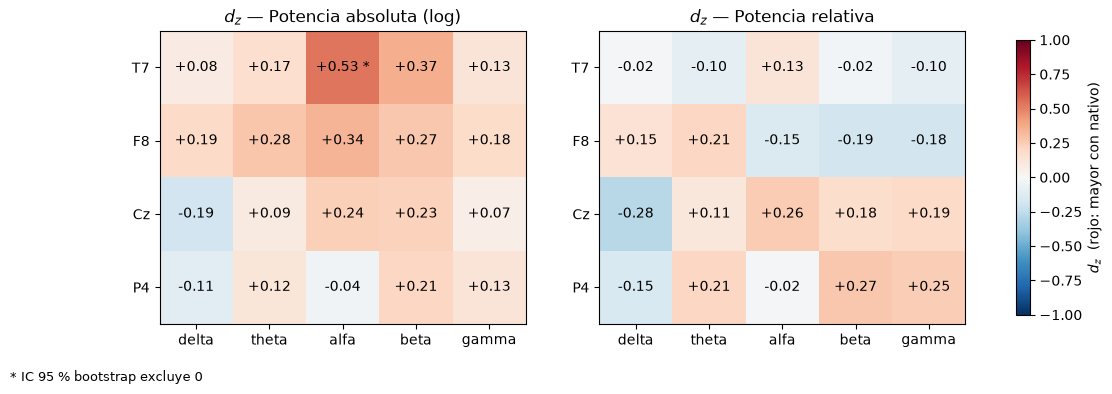

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
titulos = {'d_log_abs': 'Potencia absoluta (log)', 'd_rel_pp': 'Potencia relativa'}
for ax, var in zip(axes, titulos):
    t = efecto[efecto.descriptor == var]
    M = t.pivot(index='canal', columns='banda', values='dz').reindex(index=CANALES, columns=orden_b)
    X = t.pivot(index='canal', columns='banda', values='ic_excluye_0').reindex(index=CANALES, columns=orden_b)
    im = ax.imshow(M.values, cmap='RdBu_r', vmin=-1, vmax=1)
    for a in range(M.shape[0]):
        for b in range(M.shape[1]):
            ax.text(b, a, f"{M.values[a, b]:+.2f}{' *' if X.values[a, b] else ''}",
                    ha='center', va='center', fontsize=10)
    ax.set_xticks(range(len(orden_b)), orden_b); ax.set_yticks(range(len(CANALES)), CANALES)
    ax.set_title(f'$d_z$ — {titulos[var]}')
fig.colorbar(im, ax=axes, shrink=0.85, label='$d_z$  (rojo: mayor con nativo)')
fig.text(0.01, 0.01, '* IC 95 % bootstrap excluye 0', fontsize=9)
plt.show()

### Consistencia por sujeto
Un punto por sujeto. Las líneas grises marcan Δ = 0, y los colores distinguen el grupo de idioma. Si los italianos y los árabes quedan de lados opuestos del cero, el efecto probablemente viene de **la canción** y no del idioma (ver 4.0, diseño cruzado).

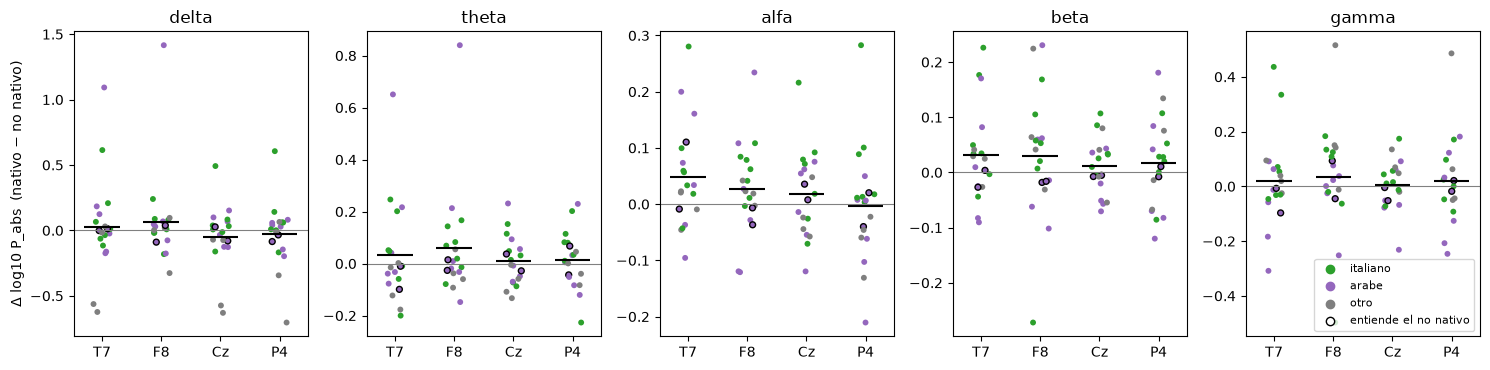

In [22]:
col_g = {'italiano': 'tab:green', 'arabe': 'tab:purple', 'otro': 'tab:gray'}
fig, axes = plt.subplots(1, len(BANDAS), figsize=(15, 3.8), sharey=False)
for ax, b in zip(axes, orden_b):
    d = dif[dif.banda == b]
    for k, ch in enumerate(CANALES):
        dd = d[d.canal == ch]
        jitter = rng.uniform(-0.15, 0.15, len(dd))
        ax.scatter(k + jitter, dd.d_log_abs, c=dd.grupo.map(col_g), s=18,
                   edgecolor=np.where(dd.entiende_no_nativo, 'k', 'none'))
        ax.hlines(dd.d_log_abs.mean(), k - 0.3, k + 0.3, color='k', lw=1.5)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(range(len(CANALES)), CANALES); ax.set_title(b)
axes[0].set_ylabel('Δ log10 P_abs  (nativo − no nativo)')
for g, c in col_g.items():
    axes[-1].scatter([], [], c=c, label=g)
axes[-1].scatter([], [], c='w', edgecolor='k', label='entiende el no nativo')
axes[-1].legend(fontsize=8, loc='best')
plt.tight_layout(); plt.show()

## 4.7 Lectura de los resultados

*Escrita con los datos actuales (19 sujetos, filtrado 0,1–40 Hz). Si cambia el preprocesamiento, hay que revisarla.*

**1. El perfil espectral es razonable.** α domina en P4 (~55 %) y baja hacia adelante. δ es alta en F8 (~40 %). θ, β y γ quedan dentro de los rangos esperados. El α posterior tan alto sugiere que los sujetos estaban relajados y posiblemente con ojos cerrados durante la escucha.

**2. F8 tiene un problema de calidad en algunos sujetos.** En s01 la potencia δ de F8 es ~100 veces la del resto (≈3300 µV² contra ≈20), y en s01, s02, s05 y s16 la δ relativa de F8 supera el 75 %. Es lo esperable para un electrodo cerca del ojo (movimientos oculares). Las **diferencias en log** son robustas a esto, porque comparan al sujeto consigo mismo, pero la **potencia relativa en F8** de esos sujetos está dominada por el artefacto. Conviene mencionarlo en limitaciones o repetir el análisis sin ellos como chequeo.

**3. Los efectos nativo vs no nativo son chicos.** Casi todos los $d_z$ están entre −0,3 y +0,4, con IC 95 % que cruzan el 0, y el % de sujetos con Δ > 0 ronda el 50 %. Con n = 19 eso no quiere decir que "no hay efecto". Quiere decir que, si existe, es menor de lo que este tamaño de muestra puede detectar.

**4. La excepción es α en T7 (potencia absoluta).** $d_z$ ≈ +0,53, IC 95 % ≈ [0,15; 0,95]: hay **más α en el temporal izquierdo con la canción nativa** (~+12 % en promedio, 13 de 19 sujetos). Dos lecturas:
- Va **en la misma dirección en italianos y árabes**, que escucharon las mismas dos canciones con los roles invertidos. Eso apunta a que el efecto se asocia al *idioma* y no a la *canción*.
- Pero es **1 de 40 comparaciones** sin corregir. Hay que ver si sobrevive a la corrección por comparaciones múltiples del paso 7 (FDR). En potencia relativa el efecto no aparece ($d_z$ ≈ 0,13), así que puede ser un aumento general de potencia en T7 más que un cambio específico de α.
- Ojo con la interpretación: la bibliografía sobre comprensión del lenguaje predice **menos** α temporal izquierda con el idioma que se entiende, o sea, la dirección contraria. En el notebook 05 (paso 7) este efecto **no sobrevive a la corrección por comparaciones múltiples** y se explica en parte por un cambio general de amplitud en T7. La discusión completa está en la sección 8.4.

**5. Para los pasos siguientes:**
- *Paso 6:* usar `potencia_bandas_largo.csv` para comparar canales (¿el efecto cambia según el electrodo?). El heatmap ya muestra que T7 se comporta distinto que P4.
- *Paso 7:* test pareado sobre `diferencias_por_sujeto.csv` (Wilcoxon) + corrección FDR, y reportar los $d_z$ de esta tabla.
- *Paso 8:* s11 y s17 entienden la canción "no nativa" (hablan italiano). Ver si sus Δ son más chicos que los del resto, y comparar el grupo `otro` (n = 4), que tiene un comportamiento distinto en δ.